# Обыкновенные дифференциальные уравнения. Практика 1
Задачи для самостоятельного решения из `Дифференциальные уравнения. Практика 1.pdf`. Каждый ответ проверяется подстановкой в уравнение в случайных точках.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import quad

x,y,C = sp.symbols('x y C')
rng = np.random.default_rng(1)
TOL = 1e-8

def sample(cond=lambda a,b:True):
    '''Случайная точка (x,y), удовлетворяющая условию области определения.'''
    while True:
        a,b = rng.uniform(.3,1.4),rng.uniform(.3,1.4)
        if cond(a,b): return a,b

def check_integral(F, f, name):
    '''F(x,y)=C — интеграл уравнения y'=f(x,y), если F_x + F_y·f = 0.'''
    res = sp.diff(F,x)+sp.diff(F,y)*f
    fn = sp.lambdify((x,y),res,'numpy')
    worst = max(abs(fn(*sample())) for _ in range(30))
    assert worst<TOL,(name,worst)
    print(f'{name}: проверено, |невязка| < {max(worst,1e-16):.0e}')

def check_explicit(sol, f, name):
    '''y=sol(x,C) — общее решение уравнения y'=f(x,y).'''
    res = sp.diff(sol,x)-f.subs(y,sol)
    fn = sp.lambdify((x,C),res,'numpy')
    worst = max(abs(fn(rng.uniform(.3,1.2),rng.uniform(-3,3))) for _ in range(30))
    assert worst<TOL,(name,worst)
    print(f'{name}: проверено, |невязка| < {max(worst,1e-16):.0e}')

## Блок А. Разделяющиеся переменные
**А1.** $y'=\dfrac xy$. $\ y\,dy=x\,dx$, поэтому $\boxed{y^2=x^2+C}$.

**А2.** $y'=e^{x+y}$. $\ e^{-y}dy=e^xdx$, откуда $-e^{-y}=e^x+C_1$, то есть $\boxed{e^{-y}=C-e^x}$.

**А3.** $y'=y\cos x$. $\ \dfrac{dy}{y}=\cos x\,dx$, поэтому $\boxed{y=Ce^{\sin x}}$ (при $C=0$ — решение $y=0$, потерянное при делении).

**А4.** $y'=\dfrac{x^2}{y(1+x^3)}$. $\ y\,dy=\dfrac{x^2dx}{1+x^3}$; замена $u=1+x^3$ даёт $\dfrac{y^2}{2}=\dfrac13\ln|1+x^3|+C_1$, то есть $\boxed{y^2=\dfrac23\ln|1+x^3|+C}$.

**А5.** $y'=1+y^2$. $\ \dfrac{dy}{1+y^2}=dx$, поэтому $\operatorname{arctg}y=x+C$, то есть $\boxed{y=\operatorname{tg}(x+C)}$.

**А6.** $y'=\dfrac yx\ln x$, $x>0$. $\ \dfrac{dy}{y}=\dfrac{\ln x}{x}dx$; замена $u=\ln x$ даёт $\ln|y|=\dfrac{\ln^2x}{2}+C_1$, то есть $\boxed{y=Ce^{\ln^2x/2}}$.

**А7.** $y'=\dfrac{e^x}{y}$. $\ y\,dy=e^xdx$, поэтому $\boxed{y^2=2e^x+C}$.

**А8.** $y'=\dfrac{1}{xy}$. $\ y\,dy=\dfrac{dx}{x}$, поэтому $\boxed{y^2=2\ln|x|+C}$.

In [2]:
check_integral(y**2-x**2,x/y,'А1')
check_integral(sp.exp(-y)+sp.exp(x),sp.exp(x+y),'А2')
check_explicit(C*sp.exp(sp.sin(x)),y*sp.cos(x),'А3')
check_integral(y**2-sp.Rational(2,3)*sp.log(1+x**3),x**2/(y*(1+x**3)),'А4')
check_explicit(sp.tan(x+C),1+y**2,'А5')
check_explicit(C*sp.exp(sp.log(x)**2/2),y/x*sp.log(x),'А6')
check_integral(y**2-2*sp.exp(x),sp.exp(x)/y,'А7')
check_integral(y**2-2*sp.log(x),1/(x*y),'А8')

А1: проверено, |невязка| < 1e-16
А2: проверено, |невязка| < 9e-16
А3: проверено, |невязка| < 1e-16
А4: проверено, |невязка| < 1e-16
А5: проверено, |невязка| < 1e-16
А6: проверено, |невязка| < 1e-16
А7: проверено, |невязка| < 1e-16
А8: проверено, |невязка| < 1e-16


## Блок Б. Линейные уравнения
Для $y'+p(x)y=q(x)$ используем интегрирующий множитель $\mu=e^{\int p\,dx}$: $(\mu y)'=\mu q$.

**Б1.** $y'+2y=4$. $\ \mu=e^{2x}$, $(e^{2x}y)'=4e^{2x}$, поэтому $\boxed{y=2+Ce^{-2x}}$.

**Б2.** $y'-y=x$. $\ \mu=e^{-x}$, $(e^{-x}y)'=xe^{-x}$. По частям $\int xe^{-x}dx=-(x+1)e^{-x}$, поэтому $\boxed{y=Ce^x-x-1}$.

**Б3.** $y'+y\operatorname{tg}x=\sin2x$. $\ \mu=\dfrac{1}{\cos x}$, $\left(\dfrac{y}{\cos x}\right)'=\dfrac{\sin 2x}{\cos x}=2\sin x$, поэтому $\boxed{y=C\cos x-2\cos^2x}$.

**Б4.** $xy'+y=x^2$, $x>0$. Левая часть равна $(xy)'$, поэтому $xy=\dfrac{x^3}{3}+C$, то есть $\boxed{y=\dfrac{x^2}{3}+\dfrac Cx}$.

**Б5.** $y'+2xy=xe^{-x^2}$. $\ \mu=e^{x^2}$, $(e^{x^2}y)'=x$, поэтому $\boxed{y=e^{-x^2}\left(\dfrac{x^2}{2}+C\right)}$.

**Б6.** $y'+y=\dfrac{1}{1+x^2}$. $\ \mu=e^x$, $(e^xy)'=\dfrac{e^x}{1+x^2}$. Этот интеграл не выражается через элементарные функции, поэтому ответ записывается с интегралом: $\boxed{y=e^{-x}\left(C+\displaystyle\int_0^x\dfrac{e^t\,dt}{1+t^2}\right)}$.

**Б7.** $y'+\dfrac2xy=x^3$, $x>0$. $\ \mu=x^2$, $(x^2y)'=x^5$, поэтому $\boxed{y=\dfrac{x^4}{6}+\dfrac{C}{x^2}}$.

**Б8.** $y'-y=e^{2x}$. $\ \mu=e^{-x}$, $(e^{-x}y)'=e^x$, поэтому $\boxed{y=e^{2x}+Ce^x}$.

In [3]:
check_explicit(2+C*sp.exp(-2*x),4-2*y,'Б1')
check_explicit(C*sp.exp(x)-x-1,x+y,'Б2')
check_explicit(C*sp.cos(x)-2*sp.cos(x)**2,sp.sin(2*x)-y*sp.tan(x),'Б3')
check_explicit(x**2/3+C/x,(x**2-y)/x,'Б4')
check_explicit(sp.exp(-x**2)*(x**2/2+C),x*sp.exp(-x**2)-2*x*y,'Б5')
check_explicit(x**4/6+C/x**2,x**3-2*y/x,'Б7')
check_explicit(sp.exp(2*x)+C*sp.exp(x),sp.exp(2*x)+y,'Б8')

# Б6: проверяем разностной производной, так как интеграл не элементарный
def y_b6(a,c=1.):
    return np.exp(-a)*(c+quad(lambda t:np.exp(t)/(1+t*t),0,a,epsabs=1e-12)[0])
for a in (.2,.7,1.5):
    h = 1e-4; d = (y_b6(a+h)-y_b6(a-h))/(2*h)
    assert abs(d+y_b6(a)-1/(1+a*a))<1e-6
print('Б6: проверено численно')

Б1: проверено, |невязка| < 1e-16
Б2: проверено, |невязка| < 1e-16
Б3: проверено, |невязка| < 9e-16
Б4: проверено, |невязка| < 7e-15
Б5: проверено, |невязка| < 1e-16
Б7: проверено, |невязка| < 1e-14
Б8: проверено, |невязка| < 1e-16
Б6: проверено численно


## Блок В. Однородные уравнения
Замена $y=ux$, $y'=u+xu'$.

**В1.** $y'=\dfrac yx$. $\ xu'=0$, поэтому $\boxed{y=Cx}$.

**В2.** $y'=\dfrac{x+y}{x-y}$. $\ xu'=\dfrac{1+u}{1-u}-u=\dfrac{1+u^2}{1-u}$. Разделяем: $\dfrac{(1-u)\,du}{1+u^2}=\dfrac{dx}{x}$, откуда $\operatorname{arctg}u-\dfrac12\ln(1+u^2)=\ln|x|+C$. Возвращаясь к $y$: $\boxed{\operatorname{arctg}\dfrac yx=\ln\sqrt{x^2+y^2}+C}$.

**В3.** $y'=\dfrac{y^2-x^2}{2xy}$. $\ xu'=\dfrac{u^2-1}{2u}-u=-\dfrac{1+u^2}{2u}$, откуда $\ln(1+u^2)=-\ln|x|+C_1$. Значит, $\boxed{x^2+y^2=Cx}$.

**В4.** $y'=\dfrac xy+\dfrac yx$. $\ xu'=\dfrac1u$, откуда $u^2=2\ln|x|+C$. Значит, $\boxed{y^2=x^2(2\ln|x|+C)}$.

**В5.** $xy'=y+xe^{y/x}$. $\ xu'=e^u$, откуда $-e^{-u}=\ln|x|+C_1$. Значит, $\boxed{e^{-y/x}=C-\ln|x|}$.

**В6.** $y'=\dfrac yx+\dfrac xy$. Это то же уравнение, что В4 (в листке задача повторяется): $\boxed{y^2=x^2(2\ln|x|+C)}$.

In [4]:
check_integral(y/x,y/x,'В1')
check_integral(sp.atan(y/x)-sp.log(x**2+y**2)/2,(x+y)/(x-y),'В2')
check_integral((x**2+y**2)/x,(y**2-x**2)/(2*x*y),'В3')
check_integral(y**2/x**2-2*sp.log(x),x/y+y/x,'В4')
check_integral(sp.exp(-y/x)+sp.log(x),y/x+sp.exp(y/x),'В5')
check_integral(y**2/x**2-2*sp.log(x),y/x+x/y,'В6')

В1: проверено, |невязка| < 1e-16
В2: проверено, |невязка| < 3e-14
В3: проверено, |невязка| < 9e-16
В4: проверено, |невязка| < 4e-15
В5: проверено, |невязка| < 6e-16
В6: проверено, |невязка| < 1e-14


## Блок Г. Сведение к системам
**Г1.** $y''+4y=0$. Пусть $y_1=y$, $y_2=y'$: $\quad y_1'=y_2,\ \ y_2'=-4y_1$.

**Г2.** $y'''-y=0$. Пусть $y_1=y$, $y_2=y'$, $y_3=y''$: $\quad y_1'=y_2,\ \ y_2'=y_3,\ \ y_3'=y_1$.

**Г3.** $y''+2y'+5y=\sin x$: $\quad y_1'=y_2,\ \ y_2'=-5y_1-2y_2+\sin x$.

**Г4.** $\theta''+\sin\theta=0$. Пусть $\theta_1=\theta$, $\theta_2=\theta'$: $\quad\theta_1'=\theta_2,\ \ \theta_2'=-\sin\theta_1$.

Проверка на Г1: решаем систему численно и сравниваем с точным решением $y=\cos2x$ при $y(0)=1$, $y'(0)=0$.

In [5]:
from scipy.integrate import solve_ivp
s = solve_ivp(lambda t,v:[v[1],-4*v[0]],[0,5],[1,0],rtol=1e-10,atol=1e-12,t_eval=np.linspace(0,5,50))
assert np.abs(s.y[0]-np.cos(2*s.t)).max()<1e-8; print('Г1: система даёт y=cos 2x')

Г1: система даёт y=cos 2x


## Блок Д. Поля направлений
Стрелки нормированы, чтобы была видна только наклонная линия поля. Цветные кривые — интегральные кривые.

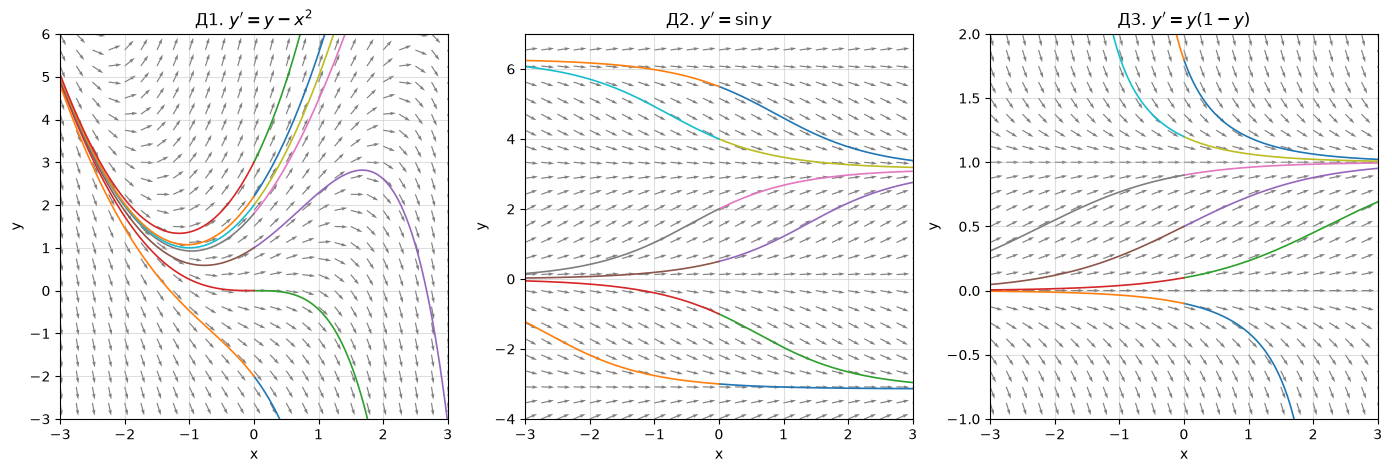

In [6]:
def field(ax,f,xlim,ylim,title,inits):
    X,Y = np.meshgrid(np.linspace(*xlim,25),np.linspace(*ylim,25))
    U,V = np.ones_like(X),f(X,Y); L = np.hypot(U,V)
    ax.quiver(X,Y,U/L,V/L,angles='xy',color='gray',width=.003,scale=30)
    for x0,y0 in inits:
        for span in ([x0,xlim[1]],[x0,xlim[0]]):
            ev = lambda t,v:abs(v[0])-50
            ev.terminal = True
            s = solve_ivp(lambda t,v:[f(t,v[0])],span,[y0],max_step=.02,events=ev)
            ax.plot(s.t,s.y[0],lw=1.2)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.grid(True,alpha=.4); ax.set_title(title)

fig,axs = plt.subplots(1,3,figsize=(17,5))
field(axs[0],lambda a,b:b-a**2,(-3,3),(-3,6),"Д1. $y'=y-x^2$",[(0,y0) for y0 in (-2,0,1,1.8,2,2.2,3)])
field(axs[1],lambda a,b:np.sin(b),(-3,3),(-4,7),"Д2. $y'=\\sin y$",[(0,y0) for y0 in (-3,-1,.5,2,4,5.5)])
field(axs[2],lambda a,b:b*(1-b),(-3,3),(-1,2),"Д3. $y'=y(1-y)$",[(0,y0) for y0 in (-.1,.1,.5,.9,1.2,1.8)])
fig.savefig('fig/DE1_fields.png',dpi=120,bbox_inches='tight'); plt.show()

**Что видно на рисунках.**
- **Д1.** Точное решение $y=x^2+2x+2+Ce^x$. Кривая с $C=0$ разделяет решения, уходящие вверх и вниз.
- **Д2.** Равновесия $y=k\pi$: устойчивы при нечётном $k$, неустойчивы при чётном $k$.
- **Д3.** Логистическое уравнение: $y=1$ — устойчивое равновесие, $y=0$ — неустойчивое.

In [7]:
check_explicit(x**2+2*x+2+C*sp.exp(x),y-x**2,'Д1, точное решение')

Д1, точное решение: проверено, |невязка| < 1e-16
